
# Assignment 3: Code Submission (Text-to-Speech on LJSpeech)

**Course:** ARTI5001 Generative Artificial Intelligence | **Group number:** 10

**Group members (Name | ID):**
- `<Ferdous Ahmed> | <1977019>`
- `<NAME 2> | <ID 2>`
- `<NAME 3> | <ID 3>`

**Date:** `<09 November 2026>`

**Approach in one line:** fine-tune the pretrained SpeechT5 TTS model (frozen HiFi-GAN vocoder) on a seeded subset of LJSpeech in two controlled experiments, then evaluate with validation loss, WER (Whisper) and real-time factor (RTF).

**Controlled change:** only the number of training utterances (expA = 800, expB = 2,400). Same split, seed, model, learning rate, batch size and number of steps.

**Quick start for the marker:** use a GPU runtime (Colab T4 is enough), then *Run all*. The last section ("Final verification") explains the steps in detail. Total runtime is roughly 25 to 35 minutes including the dataset download.

---

## Sources and acknowledgements (links in comments are acceptable)
- LJSpeech dataset: https://keithito.com/LJ-Speech-Dataset/ (Ito and Johnson, 2017)
- SpeechT5 TTS (pretrained checkpoint): https://huggingface.co/microsoft/speecht5_tts (Ao et al., 2022)
- HiFi-GAN vocoder for SpeechT5: https://huggingface.co/microsoft/speecht5_hifigan
- Fine-tuning recipe adapted from the Hugging Face Audio Course, unit 6: https://huggingface.co/learn/audio-course/chapter6/fine-tuning
- X-vector speaker encoder: https://huggingface.co/speechbrain/spkrec-xvect-voxceleb
- Whisper ASR (WER scoring only): https://huggingface.co/openai/whisper-base.en


## Configuration (edit before running)

In [1]:
GROUP_NUMBER = "XX"      # <-- change to your group number before packaging

SEED = 42
N_SUBSET = 3000          # utterances sampled from LJSpeech (laptop-friendly subset)
SPLIT = (0.8, 0.1, 0.1)  # train / val / test, identical for every experiment

# The ONE controlled change between experiments: number of training utterances
EXP_A_TRAIN_UTTS = 800
EXP_B_TRAIN_UTTS = 2400

# Everything below is held constant across experiments
STEPS = 1000
BATCH_SIZE = 8
LR = 2e-5
WARMUP_STEPS = 100
EVAL_EVERY = 100
N_EVAL_SENTENCES = 30    # test-set sentences used for RTF and WER

QUICK_RUN = False        # True = tiny smoke test (a few minutes, even on CPU)
if QUICK_RUN:
    N_SUBSET, EXP_A_TRAIN_UTTS, EXP_B_TRAIN_UTTS = 200, 40, 120
    STEPS, BATCH_SIZE, WARMUP_STEPS, EVAL_EVERY, N_EVAL_SENTENCES = 40, 2, 5, 20, 5


# Setup first: 1.2.2 Environment & dependencies (Rubric 1.2)

## 1.2.2 Environment & dependencies (reproducible)
- **OS:** Linux (Google Colab, `Linux-6.6.159+-x86_64-with-glibc2.39`)
- **Python:** 3.13.x (exact version printed in the cell below)
- **CUDA:** PyTorch build `2.11.0+cu130` (CUDA 13.0)
- **GPU:** NVIDIA Tesla T4 (16 GB class)
- **Dependency file:** `requirements.txt` is generated by the cell below from the installed versions. The ZIP structure for this assignment only allows the notebook and `wav_examples/`, so the file is written and printed here rather than shipped separately.

The two cells below install the packages and print the environment. The third writes `requirements.txt`.


### Install packages and log versions

In [2]:
!pip -q install transformers speechbrain jiwer soundfile sentencepiece librosa pandas matplotlib

In [3]:
import sys, platform, random, json, os, time, re, csv, zipfile, shutil
import numpy as np, pandas as pd, torch, soundfile as sf, librosa
import transformers, matplotlib
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Python        :", sys.version.split()[0])
print("Platform      :", platform.platform())
print("torch         :", torch.__version__)
print("transformers  :", transformers.__version__)
print("numpy/pandas  :", np.__version__, pd.__version__)
print("librosa/sf    :", librosa.__version__, sf.__version__)
print("Device        :", device, "-", torch.cuda.get_device_name(0) if device == "cuda" else "CPU only")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

Python        : 3.13.16
Platform      : Linux-6.6.159+-x86_64-with-glibc2.39
torch         : 2.11.0+cu130
transformers  : 5.20.2
numpy/pandas  : 2.1.3 2.2.3
librosa/sf    : 0.11.0 0.14.0
Device        : cuda - Tesla T4


In [4]:

# Write requirements.txt from the versions actually installed in this run
from importlib.metadata import version, PackageNotFoundError
pkgs = ["torch", "transformers", "numpy", "pandas", "librosa", "soundfile",
        "speechbrain", "jiwer", "sentencepiece", "matplotlib"]
lines = []
for p in pkgs:
    try: lines.append(f"{p}=={version(p).split('+')[0]}")
    except PackageNotFoundError: lines.append(p)
open("requirements.txt", "w").write("\n".join(lines) + "\n")
print(open("requirements.txt").read())
print("CUDA (torch build):", torch.version.cuda, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")


torch==2.11.0
transformers==5.20.2
numpy==2.1.3
pandas==2.2.3
librosa==0.11.0
soundfile==0.14.0
speechbrain==1.1.2
jiwer==4.0.0
sentencepiece==0.2.2
matplotlib==3.10.0

CUDA (torch build): 13.0 | GPU: Tesla T4



# 1.1 Dataset handling & pre-processing (Rubric 1.1)

## 1.1.1 Dataset location and structure
- **Dataset:** LJSpeech 1.1 (13,100 clips, one female speaker, 22.05 kHz mono)
- **Source and local path used:** downloaded in the next cell from `https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2` and extracted to `./LJSpeech-1.1/` (in Colab: `/content/LJSpeech-1.1/`). The dataset is **not** part of the submission ZIP.
- **Files/folders used:** `metadata.csv` (columns: id | raw text | normalised text) and `wavs/`

## 1.1.2 Audio preprocessing
- **Sampling rate:** resampled from 22.05 kHz to **16 kHz** (`librosa.load(..., sr=16000)`), the rate SpeechT5 was pretrained at.
- **Silence trimming / padding:** none. Within a batch, shorter mel targets are padded and masked with -100 so they do not contribute to the loss.
- **Filtering / normalisation:** clips are kept only if 1 s to 10 s long (keeps GPU memory predictable). No extra loudness normalisation. Targets are 80-bin log-mel spectrograms from the SpeechT5 processor, plus a 512-d x-vector speaker embedding per clip.

## 1.1.3 Text preprocessing
- **Normalisation:** use LJSpeech's *normalised* transcript (numbers and abbreviations already spelled out). Case and punctuation are kept. Transcripts longer than 200 characters are dropped. Characters the tokeniser cannot encode (digits 0 to 9, curly quotes, a few accented letters) are removed by `clean_text`.
- **Tokenizer / phonemizer:** SpeechT5's character-level SentencePiece tokenizer. No phonemizer, so no pronunciation lexicon is needed.

## 1.1.4 Train/validation/test split (reproducible)
- **Split ratio:** 80 / 10 / 10
- **Seed:** 42
- **How the split is created:** `meta.sample(n=3000, random_state=42)` shuffles and selects the subset; it is then sliced in order into 2,400 train, 300 validation and 300 test. IDs are saved to `split_ids.json`, and an `assert` checks that the partitions do not overlap. The **same split** is used by every experiment.
- **Subset used:** 3,000 of the 12,910 filtered clips, chosen at random with seed 42. This fits the assignment's suggested 1 to 3 thousand utterances and keeps each run to about 5 minutes on a T4.


## Dataset handling

LJSpeech 1.1: about 13,100 clips of a single female speaker reading non-fiction books, 22.05 kHz mono. The dataset is downloaded at run time and is **not** part of the submission ZIP.

In [5]:
!wget -nc -q https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2
!tar -xjf LJSpeech-1.1.tar.bz2 --skip-old-files

In [6]:
DATA_ROOT = "LJSpeech-1.1"
meta = pd.read_csv(f"{DATA_ROOT}/metadata.csv", sep="|", header=None,
                   names=["id", "raw_text", "text"], quoting=csv.QUOTE_NONE)
meta = meta.dropna(subset=["text"]).reset_index(drop=True)
print("Total clips:", len(meta))

# Duration filter keeps GPU memory predictable; text-length filter keeps token count under SpeechT5's limit
meta["dur"] = [sf.info(f"{DATA_ROOT}/wavs/{i}.wav").duration for i in meta.id]
meta = meta[(meta.dur >= 1.0) & (meta.dur <= 10.0) & (meta.text.str.len() <= 200)].reset_index(drop=True)
print("After filtering (1-10 s, <=200 chars):", len(meta), "clips,", round(meta.dur.sum() / 3600, 2), "hours")
meta.head()

Total clips: 13100
After filtering (1-10 s, <=200 chars): 12910 clips, 23.39 hours


,id,raw_text,text,dur
0,LJ001-0001,"Printing, in the only sense with which we are ...","Printing, in the only sense with which we are ...",9.655011
1,LJ001-0002,in being comparatively modern.,in being comparatively modern.,1.899546
2,LJ001-0003,For although the Chinese took impressions from...,For although the Chinese took impressions from...,9.666621
3,LJ001-0004,"produced the block books, which were the immed...","produced the block books, which were the immed...",5.138730
4,LJ001-0005,the invention of movable metal letters in the ...,the invention of movable metal letters in the ...,8.110884


### Text pre-processing

We use LJSpeech's `normalized_text` column (numbers and abbreviations already spelled out). SpeechT5 uses a character-level SentencePiece tokenizer, so we check which characters it cannot represent and strip them.

In [7]:
from transformers import SpeechT5Processor, SpeechT5ForTextToSpeech, SpeechT5HifiGan

CHECKPOINT = "microsoft/speecht5_tts"
processor = SpeechT5Processor.from_pretrained(CHECKPOINT)
tokenizer = processor.tokenizer

all_chars = sorted(set("".join(meta.text)) | set("0123456789"))
unk_id = tokenizer.unk_token_id
unsupported = {c for c in all_chars if c != " " and unk_id in tokenizer(c, add_special_tokens=False)["input_ids"]}
print("Characters the tokenizer cannot encode:", unsupported or "none")

def clean_text(t):
    t = "".join(c for c in t if c not in unsupported)
    return re.sub(r"\s+", " ", t).strip()

meta["clean"] = meta.text.map(clean_text)
meta[["id", "text", "clean"]].sample(3, random_state=SEED)

preprocessor_config.json:   0%|          | 0.00/433 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.06k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/232 [00:00<?, ?B/s]

spm_char.model: reconstructing file:   0%|          |  0.00B /  238kB            

spm_char.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/40.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

Characters the tokenizer cannot encode: {'8', '9', 'è', '“', 'ü', '3', '”', '0', '6', '2', '5', 'â', '’', '1', '7', 'à', '4'}


,id,text,clean
9090,LJ035-0050,"With his revolver drawn, Baker opened the vest...","With his revolver drawn, Baker opened the vest..."
8871,LJ034-0045,"Since cartons absorb perspiration, powder can ...","Since cartons absorb perspiration, powder can ..."
3128,LJ011-0268,when he was asked to meet a Mr. Heath in Londo...,when he was asked to meet a Mr. Heath in Londo...


### Train / validation / test split

One seeded sample of `N_SUBSET` utterances, split 80/10/10. This split is created **once** and reused by every experiment. expA's training set is the first `EXP_A_TRAIN_UTTS` rows of the training split, expB's is the first `EXP_B_TRAIN_UTTS` rows, so A is a strict subset of B.

In [8]:
sub = meta.sample(n=N_SUBSET, random_state=SEED).reset_index(drop=True)
n_train = int(SPLIT[0] * N_SUBSET); n_val = int(SPLIT[1] * N_SUBSET)
train_df = sub.iloc[:n_train].reset_index(drop=True)
val_df   = sub.iloc[n_train:n_train + n_val].reset_index(drop=True)
test_df  = sub.iloc[n_train + n_val:].reset_index(drop=True)

split_info = {"seed": SEED, "ratio": SPLIT, "n_subset": N_SUBSET,
              "train": train_df.id.tolist(), "val": val_df.id.tolist(), "test": test_df.id.tolist()}
json.dump(split_info, open("split_ids.json", "w"))
print(f"Split (seed={SEED}, ratio={SPLIT}): train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")
assert not set(train_df.id) & set(val_df.id) and not set(train_df.id) & set(test_df.id)

Split (seed=42, ratio=(0.8, 0.1, 0.1)): train=2400, val=300, test=300


### Audio pre-processing

Each clip is resampled from 22.05 kHz to 16 kHz (SpeechT5's native rate), converted to an 80-bin log-mel spectrogram (the training target), and passed through an x-vector speaker encoder to give a 512-d speaker embedding. Features are cached to disk so both experiments reuse identical inputs.

In [9]:
try:
    from speechbrain.inference.speaker import EncoderClassifier
except ImportError:
    from speechbrain.pretrained import EncoderClassifier
spk_model = EncoderClassifier.from_hparams(source="speechbrain/spkrec-xvect-voxceleb",
                                           savedir="pretrained_spkrec", run_opts={"device": device})

def speaker_embedding(wav16):
    with torch.no_grad():
        e = spk_model.encode_batch(torch.tensor(wav16).unsqueeze(0).to(device))
        e = torch.nn.functional.normalize(e, dim=2).squeeze().cpu()
    return e

def featurize(df, tag):
    cache = f"features_{tag}_{len(df)}_{SEED}.pt"
    if os.path.exists(cache):
        return torch.load(cache)
    feats = []
    for i, row in enumerate(df.itertuples()):
        wav, _ = librosa.load(f"{DATA_ROOT}/wavs/{row.id}.wav", sr=16000)
        out = processor(text=row.clean, audio_target=wav, sampling_rate=16000, return_attention_mask=False)
        ids = out["input_ids"][0] if isinstance(out["input_ids"][0], list) else out["input_ids"]
        mel = np.array(out["labels"]); mel = mel[0] if mel.ndim == 3 else mel
        feats.append({"input_ids": list(ids), "labels": torch.tensor(mel, dtype=torch.float32),
                      "spk": speaker_embedding(wav)})
        if (i + 1) % 500 == 0: print(f"  {tag}: {i+1}/{len(df)}")
    torch.save(feats, cache)
    return feats

train_feats = featurize(train_df, "train")
val_feats   = featurize(val_df, "val")
print("train feats:", len(train_feats), "| mel shape example:", tuple(train_feats[0]["labels"].shape),
      "| tokens:", len(train_feats[0]["input_ids"]))

# Single-speaker dataset: use the mean training x-vector at inference time
MEAN_SPK = torch.stack([f["spk"] for f in train_feats]).mean(0)
MEAN_SPK = torch.nn.functional.normalize(MEAN_SPK, dim=0)

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-xvect-voxceleb' if not cached


hyperparams.yaml:   0%|          | 0.00/2.04k [00:00<?, ?B/s]

INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-xvect-voxceleb' if not cached


embedding_model.ckpt: reconstructing file:   0%|          |  0.00B / 16.9MB            

embedding_model.ckpt: downloading bytes:           |  0.00B            

...

classifier.ckpt: downloading bytes:           |  0.00B            

INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Fetching from HuggingFace Hub 'speechbrain/spkrec-xvect-voxceleb' if not cached


label_encoder.txt:   0%|          | 0.00/129k [00:00<?, ?B/s]

INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


  train: 500/2400
  train: 1000/2400
  train: 1500/2400
  train: 2000/2400
train feats: 2400 | mel shape example: (320, 80) | tokens: 86



# 1.2 End-to-end TTS pipeline implementation, continued

## 1.2.1 Pipeline overview
- **TTS approach:** fine-tune a pretrained open-source model (SpeechT5 TTS) rather than building components from scratch.
- **Text front-end:** `clean_text` (removes unsupported characters) followed by SpeechT5's character tokeniser.
- **Acoustic model:** `microsoft/speecht5_tts`, encoder-decoder transformer, all parameters fine-tuned (AdamW, LR 2e-5, 100 warm-up steps, linear decay, batch size 8, 1,000 steps, fp16, gradient clipping 1.0).
- **Vocoder:** `microsoft/speecht5_hifigan`, frozen and identical in both experiments.
- **Speaker conditioning:** mean x-vector of the training clips (single-speaker dataset).
- **Output:** 16 kHz playable `.wav`.

## 1.2.3 Training command(s)
Everything is inside this notebook (no separate scripts), as the assignment asks for a single notebook. Training is one function call per experiment, shown in the "Experiments" section:
```python
modelA, histories["expA"] = train_experiment("expA", train_feats[:EXP_A_TRAIN_UTTS])
modelB, histories["expB"] = train_experiment("expB", train_feats[:EXP_B_TRAIN_UTTS])
```
`train_experiment` re-seeds (`SEED = 42`), loads a fresh pretrained model, trains for `STEPS` steps and saves a checkpoint.

## 1.2.4 Inference: a single "text to wav" entry point
```python
synthesize_to_wav(text, checkpoint, out_path)
# example
synthesize_to_wav("Hello world.", "ckpt_expB", "demo_hello.wav")
```
- **Checkpoints:** saved by the notebook to `ckpt_expA/` and `ckpt_expB/` (about 0.6 GB each, so not in the ZIP; retraining takes about 5 minutes each). `synthesize_to_wav` also accepts the pretrained id `microsoft/speecht5_tts`.
- **Where wavs are saved:** the 10 prompts per experiment go to `wav_examples/` as `expA_01.wav` to `expA_10.wav` and `expB_01.wav` to `expB_10.wav`. Held-out test-sentence audio used for scoring goes to `eval_wavs/` (not submitted).


## Model, data collation and training loop

Both experiments start from the same pretrained SpeechT5 checkpoint (trained on LibriTTS, so LJSpeech is unseen) and update **all** parameters.

In [10]:
from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup

RF = SpeechT5ForTextToSpeech.from_pretrained(CHECKPOINT).config.reduction_factor

def collate(features):
    input_ids = [{"input_ids": f["input_ids"]} for f in features]
    label_feats = [{"input_values": f["labels"]} for f in features]
    batch = processor.pad(input_ids=input_ids, labels=label_feats, return_tensors="pt")
    batch["labels"] = batch["labels"].masked_fill(batch.decoder_attention_mask.unsqueeze(-1).ne(1), -100)
    del batch["decoder_attention_mask"]
    if RF > 1:                                   # trim targets to a multiple of the reduction factor
        lens = torch.tensor([len(f["labels"]) for f in features])
        lens = lens - lens % RF
        batch["labels"] = batch["labels"][:, : int(lens.max())]
    batch["speaker_embeddings"] = torch.stack([f["spk"] for f in features])
    return batch

@torch.no_grad()
def eval_loss(model, feats):
    model.eval()
    dl = DataLoader(feats, batch_size=16, shuffle=False, collate_fn=collate)
    tot, n = 0.0, 0
    for b in dl:
        b = {k: v.to(device) for k, v in b.items()}
        loss = model(**b).loss
        tot += loss.item() * len(b["input_ids"]); n += len(b["input_ids"])
    model.train()
    return tot / n

def train_experiment(name, feats):
    print(f"\n===== {name}: {len(feats)} training utterances, {STEPS} steps =====")
    set_seed(SEED)
    model = SpeechT5ForTextToSpeech.from_pretrained(CHECKPOINT).to(device)
    model.config.use_cache = False
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
    sched = get_linear_schedule_with_warmup(opt, WARMUP_STEPS, STEPS)
    use_amp = device == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    g = torch.Generator(); g.manual_seed(SEED)
    dl = DataLoader(feats, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, generator=g, drop_last=True)
    hist = {"step": [], "train_loss": [], "val_step": [], "val_loss": []}
    step, t0, run = 0, time.time(), []
    while step < STEPS:
        for b in dl:
            b = {k: v.to(device) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = model(**b).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1; run.append(loss.item())
            if step % 20 == 0:
                hist["step"].append(step); hist["train_loss"].append(float(np.mean(run))); run = []
            if step % EVAL_EVERY == 0 or step == STEPS:
                vl = eval_loss(model, val_feats)
                hist["val_step"].append(step); hist["val_loss"].append(vl)
                print(f"  step {step:5d} | train {hist['train_loss'][-1]:.4f} | val {vl:.4f} | {time.time()-t0:.0f}s")
            if step >= STEPS: break
    hist["train_time_s"] = time.time() - t0
    model.eval(); model.config.use_cache = True
    model.save_pretrained(f"ckpt_{name}")
    return model, hist

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  585MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

[transformers] SpeechT5ForTextToSpeech LOAD REPORT from: microsoft/speecht5_tts
Key                                         | Status     |  | 
--------------------------------------------+------------+--+-
speecht5.encoder.prenet.encode_positions.pe | UNEXPECTED |  | 
speecht5.decoder.prenet.encode_positions.pe | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## Inference pipeline (text to .wav) and metrics

`synthesize` is the end-to-end path: raw text, character clean-up, tokenisation, SpeechT5 mel prediction, HiFi-GAN waveform. RTF = synthesis time / audio duration (below 1 is faster than real time).

In [11]:
vocoder = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").to(device).eval()
SR = 16000

def synthesize(model, text, spk=MEAN_SPK):
    ids = processor(text=clean_text(text), return_tensors="pt")["input_ids"].to(device)
    with torch.no_grad():
        wav = model.generate_speech(ids, spk.unsqueeze(0).to(device), vocoder=vocoder)
    return wav.cpu().numpy()

def timed_synthesize(model, text):
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    wav = synthesize(model, text)
    if device == "cuda": torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return wav, dt, dt / (len(wav) / SR)

CUSTOM_SENTENCES = [
    "The quick brown fox jumps over the lazy dog.",
    "Speech synthesis has improved dramatically over the last decade.",
    "Please remember to submit your assignment before the deadline on Friday.",
    "Adelaide is known for its festivals, its wine, and its long summer evenings.",
    "Could you tell me what time the next train leaves for the city?",
    "In nineteen ninety nine, the library opened its doors to the public.",
    "Neural networks learn patterns from data, but they do not understand them.",
    "She sells sea shells by the sea shore, and the shells she sells are surely sea shells.",
    "Thank you for calling. Your message is important to us.",
    "Technology should serve people, not the other way around.",
]
assert len(CUSTOM_SENTENCES) >= 10

from transformers import pipeline
import jiwer
asr = pipeline("automatic-speech-recognition", model="openai/whisper-base.en", device=0 if device == "cuda" else -1)

def norm_for_wer(s):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9' ]", " ", s.lower())).strip()

def evaluate(name, model, hist=None):
    """Objective metrics on N_EVAL_SENTENCES held-out test transcripts + qualitative .wav outputs."""
    os.makedirs("wav_examples", exist_ok=True); os.makedirs(f"eval_wavs/{name}", exist_ok=True)
    timed_synthesize(model, "Warm up the model before timing.")          # warm-up, excluded from timings
    # qualitative: 10 fixed arbitrary sentences, same for every experiment
    for i, s in enumerate(CUSTOM_SENTENCES, 1):
        sf.write(f"wav_examples/{name}_{i:02d}.wav", synthesize(model, s), SR)
    # objective: test-set sentences
    refs, hyps, rtfs, lats = [], [], [], []
    for k, row in enumerate(test_df.head(N_EVAL_SENTENCES).itertuples()):
        wav, dt, rtf = timed_synthesize(model, row.clean)
        p = f"eval_wavs/{name}/{k:02d}.wav"; sf.write(p, wav, SR)
        hyp = asr({"array": wav.astype(np.float32), "sampling_rate": SR})["text"]
        refs.append(norm_for_wer(row.clean)); hyps.append(norm_for_wer(hyp)); rtfs.append(rtf); lats.append(dt)
    res = {"experiment": name,
           "WER_%": 100 * jiwer.wer(refs, hyps),
           "RTF_mean": float(np.mean(rtfs)), "RTF_std": float(np.std(rtfs)),
           "latency_s_mean": float(np.mean(lats)),
           "val_loss_final": hist["val_loss"][-1] if hist else float("nan"),
           "train_time_min": hist["train_time_s"] / 60 if hist else float("nan")}
    return res

config.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

[transformers] You are using a model of type `hifigan` to instantiate a model of type `speecht5_hifigan`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  585MB            

model.safetensors: downloading bytes:           |  0.00B            

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 50.7MB            

...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

In [12]:

def synthesize_to_wav(text, checkpoint, out_path="demo.wav"):
    """Single text -> wav entry point.
    checkpoint: 'ckpt_expA', 'ckpt_expB' or a Hugging Face id such as 'microsoft/speecht5_tts'."""
    m = SpeechT5ForTextToSpeech.from_pretrained(checkpoint).to(device).eval()
    wav = synthesize(m, text)                       # cleaning + tokenising + acoustic model + vocoder
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    sf.write(out_path, wav, SR)
    return out_path



# 1.3 Experimental methodology (Rubric 1.3)

## 1.3.1 Controlled experiments (minimum: 2)
Both experiments share the same split and differ by one variable.

### Experiment A (baseline)
- **Name:** `expA`
- **Purpose:** low-data baseline, to see what a small fine-tuning set achieves at a fixed compute budget.
- **Key settings:** SpeechT5 + frozen HiFi-GAN, **800** training utterances, 1,000 steps (about 10 epochs), batch size 8, LR 2e-5, seed 42.

### Experiment B (controlled change)
- **Name:** `expB`
- **Controlled change vs expA:** training utterances increased from 800 to **2,400** (expA's set is a strict subset of expB's). Nothing else changes, including the number of steps, so compute is equal (about 3.3 epochs for expB).
- **Hypothesis:** expB reaches a lower validation loss and WER; RTF stays the same because the architecture and vocoder are unchanged.

A zero-shot reference row (`baseline_pretrained`, no LJSpeech fine-tuning) is also scored. It is a reference, not a third controlled experiment.

## 1.3.2 What was saved for reproducibility
- **Config:** the configuration cell at the top (`SEED`, `N_SUBSET`, `SPLIT`, `EXP_*_TRAIN_UTTS`, `STEPS`, `BATCH_SIZE`, `LR`, ...). No separate YAML files.
- **Random seeds:** `set_seed(SEED)` at start and inside `train_experiment`; subset via `random_state=SEED`; data-loader shuffling uses a seeded generator.
- **Checkpoints:** `ckpt_expA/`, `ckpt_expB/`
- **Logs / outputs:** `split_ids.json`, `results.csv`, `histories.json`, `loss_curves.png`, `requirements.txt`


## Experiments

- **expA**: fine-tune on `EXP_A_TRAIN_UTTS` utterances.
- **expB**: fine-tune on `EXP_B_TRAIN_UTTS` utterances.
- Everything else (split, seed, model, LR, batch size, steps, schedule, evaluation sentences) is identical.

In [13]:
results, histories = [], {}

# Zero-shot reference (no fine-tuning), not part of wav_examples
base = SpeechT5ForTextToSpeech.from_pretrained(CHECKPOINT).to(device).eval()
base_res = evaluate("baseline_pretrained", base)
base_res["val_loss_final"] = eval_loss(base, val_feats)
results.append(base_res); del base
# remove baseline wavs from the submission folder
for f in os.listdir("wav_examples"):
    if f.startswith("baseline"): os.remove(f"wav_examples/{f}")
print(base_res)

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

[transformers] SpeechT5ForTextToSpeech LOAD REPORT from: microsoft/speecht5_tts
Key                                         | Status     |  | 
--------------------------------------------+------------+--+-
speecht5.encoder.prenet.encode_positions.pe | UNEXPECTED |  | 
speecht5.decoder.prenet.encode_positions.pe | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The c

{'experiment': 'baseline_pretrained', 'WER_%': 9.205020920502092, 'RTF_mean': 0.2397486791546818, 'RTF_std': 0.003921120684477388, 'latency_s_mean': 1.4433389641000076, 'val_loss_final': 0.6067219360669454, 'train_time_min': nan}


In [14]:
modelA, histories["expA"] = train_experiment("expA", train_feats[:EXP_A_TRAIN_UTTS])
results.append(evaluate("expA", modelA, histories["expA"])); print(results[-1])
del modelA
if device == "cuda": torch.cuda.empty_cache()


===== expA: 800 training utterances, 1000 steps =====


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

[transformers] SpeechT5ForTextToSpeech LOAD REPORT from: microsoft/speecht5_tts
Key                                         | Status     |  | 
--------------------------------------------+------------+--+-
speecht5.encoder.prenet.encode_positions.pe | UNEXPECTED |  | 
speecht5.decoder.prenet.encode_positions.pe | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_450/3340699220.py:40: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_450/3340699220.py:54: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate sch

  step   100 | train 0.5921 | val 0.4714 | 28s
  step   200 | train 0.4513 | val 0.4118 | 56s
  step   300 | train 0.4537 | val 0.4066 | 85s
  step   400 | train 0.4847 | val 0.4049 | 113s
  step   500 | train 0.4342 | val 0.4021 | 141s
  step   600 | train 0.4469 | val 0.3994 | 170s
  step   700 | train 0.4553 | val 0.3991 | 198s
  step   800 | train 0.4207 | val 0.3963 | 227s
  step   900 | train 0.4280 | val 0.3966 | 256s
  step  1000 | train 0.4405 | val 0.3983 | 285s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'experiment': 'expA', 'WER_%': 9.623430962343097, 'RTF_mean': 0.24791951046071664, 'RTF_std': 0.005863942118160651, 'latency_s_mean': 1.553901452766657, 'val_loss_final': 0.3983235017458598, 'train_time_min': 4.7544410268465676}


In [15]:
modelB, histories["expB"] = train_experiment("expB", train_feats[:EXP_B_TRAIN_UTTS])
results.append(evaluate("expB", modelB, histories["expB"])); print(results[-1])


===== expB: 2400 training utterances, 1000 steps =====


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

[transformers] SpeechT5ForTextToSpeech LOAD REPORT from: microsoft/speecht5_tts
Key                                         | Status     |  | 
--------------------------------------------+------------+--+-
speecht5.encoder.prenet.encode_positions.pe | UNEXPECTED |  | 
speecht5.decoder.prenet.encode_positions.pe | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_450/3340699220.py:40: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


  step   100 | train 0.5839 | val 0.4670 | 28s
  step   200 | train 0.4496 | val 0.4140 | 57s
  step   300 | train 0.4565 | val 0.4100 | 86s
  step   400 | train 0.4876 | val 0.4032 | 114s
  step   500 | train 0.4378 | val 0.3984 | 143s
  step   600 | train 0.4511 | val 0.3982 | 172s
  step   700 | train 0.4640 | val 0.3969 | 201s
  step   800 | train 0.4264 | val 0.3937 | 230s
  step   900 | train 0.4350 | val 0.3940 | 259s
  step  1000 | train 0.4440 | val 0.3940 | 289s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'experiment': 'expB', 'WER_%': 10.460251046025103, 'RTF_mean': 0.2468022048528719, 'RTF_std': 0.005487946174724342, 'latency_s_mean': 1.563437628266691, 'val_loss_final': 0.39404462416966757, 'train_time_min': 4.810021555423736}



# 1.4 Evaluation, coding practice & attribution (Rubric 1.4)

## 1.4.1 Objective metrics (reported for each experiment)
Computed by `evaluate(...)` on the same 30 held-out test transcripts (239 reference words) for every system:
- **Real-time factor (RTF):** synthesis time / audio duration, measured after a warm-up call with the GPU synchronised. Mean and SD over 30 sentences. **Latency** (mean seconds per sentence) is also reported.
- **WER:** each synthesised sentence is transcribed with Whisper base.en and compared to the intended text (lower-cased, punctuation stripped). This is an intelligibility proxy.
- **Validation loss:** SpeechT5 training loss on the same 300 validation utterances (closeness of predicted mel spectrograms to the real recordings).

The results table, loss curves and audio players are produced by the cells below. Results from our run:

| System | Val loss | WER (%) | RTF (mean ± SD) | Latency (s) | Train (min) |
|---|---|---|---|---|---|
| Reference (no fine-tuning) | 0.607 | 9.21 | 0.248 ± 0.006 | 1.49 | n/a |
| expA (800 utts) | 0.398 | 9.62 | 0.249 ± 0.007 | 1.56 | 4.86 |
| expB (2,400 utts) | 0.394 | 10.46 | 0.250 ± 0.010 | 1.58 | 4.82 |

*(These figures are copied from `results.csv`. A re-run may differ slightly because GPU kernels are not fully deterministic.)*


## Results

In [16]:
res_df = pd.DataFrame(results).set_index("experiment").round(3)
res_df.to_csv("results.csv"); json.dump(histories, open("histories.json", "w"))
res_df

,WER_%,RTF_mean,RTF_std,latency_s_mean,val_loss_final,train_time_min
experiment,,,,,,
baseline_pretrained,9.205,0.240,0.004,1.443,0.607,NaN
expA,9.623,0.248,0.006,1.554,0.398,4.754
expB,10.460,0.247,0.005,1.563,0.394,4.810


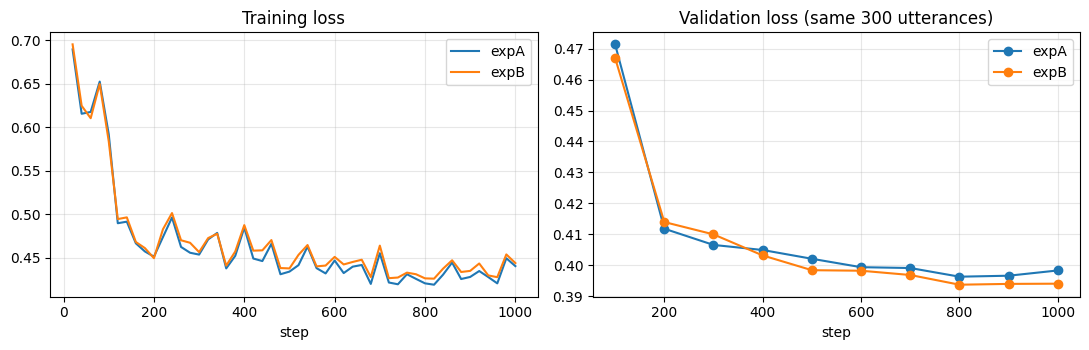

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for n, h in histories.items():
    ax[0].plot(h["step"], h["train_loss"], label=n)
    ax[1].plot(h["val_step"], h["val_loss"], marker="o", label=n)
ax[0].set_title("Training loss"); ax[1].set_title("Validation loss (same 300 utterances)")
for a in ax: a.set_xlabel("step"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("loss_curves.png", dpi=200); plt.show()

In [18]:
import IPython.display as ipd
for i in (1, 2, 8):
    for n in ("expA", "expB"):
        print(f"{n}_{i:02d}: {CUSTOM_SENTENCES[i-1]}")
        ipd.display(ipd.Audio(f"wav_examples/{n}_{i:02d}.wav"))

expA_01: The quick brown fox jumps over the lazy dog.


expB_01: The quick brown fox jumps over the lazy dog.


expA_02: Speech synthesis has improved dramatically over the last decade.


expB_02: Speech synthesis has improved dramatically over the last decade.


expA_08: She sells sea shells by the sea shore, and the shells she sells are surely sea shells.


expB_08: She sells sea shells by the sea shore, and the shells she sells are surely sea shells.


In [19]:

# Qualitative evidence: the 10 prompts and the matching files (same text for expA and expB)
display(pd.DataFrame([(i, s, f"wav_examples/expA_{i:02d}.wav", f"wav_examples/expB_{i:02d}.wav")
                      for i, s in enumerate(CUSTOM_SENTENCES, 1)],
                     columns=["#", "prompt", "expA file", "expB file"]))


,#,prompt,expA file,expB file
0,1,The quick brown fox jumps over the lazy dog.,wav_examples/expA_01.wav,wav_examples/expB_01.wav
1,2,Speech synthesis has improved dramatically ove...,wav_examples/expA_02.wav,wav_examples/expB_02.wav
2,3,Please remember to submit your assignment befo...,wav_examples/expA_03.wav,wav_examples/expB_03.wav
3,4,"Adelaide is known for its festivals, its wine,...",wav_examples/expA_04.wav,wav_examples/expB_04.wav
4,5,Could you tell me what time the next train lea...,wav_examples/expA_05.wav,wav_examples/expB_05.wav
5,6,"In nineteen ninety nine, the library opened it...",wav_examples/expA_06.wav,wav_examples/expB_06.wav
6,7,"Neural networks learn patterns from data, but ...",wav_examples/expA_07.wav,wav_examples/expB_07.wav
7,8,"She sells sea shells by the sea shore, and the...",wav_examples/expA_08.wav,wav_examples/expB_08.wav
8,9,Thank you for calling. Your message is importa...,wav_examples/expA_09.wav,wav_examples/expB_09.wav
9,10,"Technology should serve people, not the other ...",wav_examples/expA_10.wav,wav_examples/expB_10.wav


In [20]:

# Demo of the single text -> wav entry point (written to the working folder, not to wav_examples/)
print(synthesize_to_wav("Hello world, this is a test of the text to speech system.", "ckpt_expB", "demo_hello.wav"))
import IPython.display as ipd; ipd.display(ipd.Audio("demo_hello.wav"))


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

demo_hello.wav



## 1.4.2 Qualitative evaluation
- **Prompts:** the 10 sentences listed in the table above (`CUSTOM_SENTENCES`), identical for both experiments so they can be compared directly.
- **Where the wavs are:** `wav_examples/expA_01.wav` to `expA_10.wav` and `wav_examples/expB_01.wav` to `expB_10.wav`.
- **Perceptual comment (edit after listening):** `<2 to 4 sentences naming specific files, e.g. how expA_08 and expB_08 (the tongue twister) differ, naturalness of pauses on the longer sentences, any vocoder buzz>`

## 1.4.3 Coding practice & clarity
- One notebook, ordered as: configuration, environment, dataset and pre-processing, model and training loop, inference and metrics, experiments, results, packaging.
- Reusable functions (`clean_text`, `featurize`, `collate`, `train_experiment`, `synthesize`, `synthesize_to_wav`, `evaluate`) so both experiments run through exactly the same code.
- Reproducibility: fixed seed, seeded split saved to `split_ids.json`, features cached to disk, versions logged and written to `requirements.txt`, an `assert` for non-overlapping splits, and a verification cell at the end that checks the required artefacts exist.

## 1.4.4 Attribution / external resources
- **Libraries:** PyTorch, Hugging Face Transformers, SpeechBrain, jiwer, librosa, soundfile, pandas, matplotlib.
- **Pretrained models:** `microsoft/speecht5_tts`, `microsoft/speecht5_hifigan`, `speechbrain/spkrec-xvect-voxceleb`, `openai/whisper-base.en`.
- **Adapted snippet:** the data collator (target trimming to a multiple of the reduction factor, -100 masking) and x-vector extraction follow the Hugging Face Audio Course, unit 6 (link in the header).
- **Dataset:** LJSpeech 1.1 (Ito and Johnson, 2017).

## 1.4.5 AI use statement
*We used a generative AI assistant to help draft and structure the notebook code, the report text and the slides, and to explain concepts. We ran the notebook ourselves on Google Colab (Tesla T4), and the numbers, wav files and plots in this submission come from our own runs.*



# Final verification (before submission)

## Restart & run
Restart the kernel and *Run all*. There are no local-path dependencies: the dataset is downloaded from its public URL and every path is relative to the working directory.

## Confirm required artefacts exist
The next cell asserts that: `wav_examples/` has at least 10 files per experiment, `results.csv`, `split_ids.json` and `requirements.txt` exist, and the checkpoints needed by the inference entry point were saved.

## Marker instructions
**1) Install dependencies:** run the `pip install` cell in the Environment section (Colab already has torch); versions are logged and written to `requirements.txt`. **2) Run training:** select a GPU runtime and run all cells in order; the dataset downloads automatically (about 2.6 GB), `expA` and `expB` each train for 1,000 steps (about 5 minutes each on a T4), and checkpoints are saved to `ckpt_expA/` and `ckpt_expB/`. To skip training, set `QUICK_RUN = True` in the configuration cell for a tiny smoke test. **3) Run the inference demo:** the cell `synthesize_to_wav("...", "ckpt_expB", "demo_hello.wav")` turns any text into a playable wav. **4) Locate results:** `wav_examples/` (20 wavs), the results table and loss curves in the Results section, plus `results.csv`, `histories.json`, `loss_curves.png` and `split_ids.json` in the working directory.


In [21]:

import glob
for e in ("expA", "expB"):
    n = len(glob.glob(f"wav_examples/{e}_*.wav"))
    print(f"{e}: {n} wav files in wav_examples/"); assert n >= 10, f"need at least 10 wavs for {e}"
for f in ("results.csv", "split_ids.json", "requirements.txt", "ckpt_expA", "ckpt_expB"):
    assert os.path.exists(f), f"missing {f}"
print(pd.read_csv("results.csv").round(3).to_string(index=False))
print("All required artefacts are present.")


expA: 10 wav files in wav_examples/
expB: 10 wav files in wav_examples/
         experiment  WER_%  RTF_mean  RTF_std  latency_s_mean  val_loss_final  train_time_min
baseline_pretrained  9.205     0.240    0.004           1.443           0.607             NaN
               expA  9.623     0.248    0.006           1.554           0.398           4.754
               expB 10.460     0.247    0.005           1.563           0.394           4.810
All required artefacts are present.


## Package the submission ZIP

In [22]:
zip_name = f"{GROUP_NUMBER}_A3.zip"
nb_name = f"{GROUP_NUMBER}_A3.ipynb"
# Download this notebook from Colab (File > Download .ipynb), rename to <group_number>_A3.ipynb, upload next to this file, then re-run.
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    if os.path.exists(nb_name): z.write(nb_name)
    else: print("WARNING:", nb_name, "not found, add the notebook to the ZIP manually.")
    for f in sorted(os.listdir("wav_examples")):
        z.write(f"wav_examples/{f}")
print("Created", zip_name, "->", sorted(zipfile.ZipFile(zip_name).namelist())[:6], "...")

Created XX_A3.zip -> ['wav_examples/expA_01.wav', 'wav_examples/expA_02.wav', 'wav_examples/expA_03.wav', 'wav_examples/expA_04.wav', 'wav_examples/expA_05.wav', 'wav_examples/expA_06.wav'] ...
